# $L = 6$ trial, one sample

Nine projector runs of sample 0 on the periodic $6\times 6$ torus, $N = 108$. The couplings are $J_b = \sigma z_b$ with one stored standard normal $z_b$. The fields are the three ratios $\Gamma/\sigma = 1, 2, 3$, so $\sigma = 0.05$ is plotted at $\Gamma = 0.05, 0.10, 0.15$.

Against $\Gamma$, those three points sit near the origin and the $\sigma = 2$ points sit at $2, 4, 6$. Against $\Gamma/\sigma$, every standard deviation is drawn at $1, 2, 3$. That common axis is the one the curves are meant to share: $H(\sigma, \Gamma) = \sigma\, H(1, \Gamma/\sigma)$, so a dimensionless observable depends on $\Gamma$ only through $\Gamma/\sigma$.

This is one sample, not a disorder average. Each run kept one ancestral line, and $q_2$ sits on $1/N$.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent
base = root / "data" / "kagome" / "gaussian_nn" / "pbc" / "L6" / "pqmc" / "h0"

def token(value):
    text = f"{float(value):.8f}".rstrip("0").rstrip(".")
    if text in ("", "-0"):
        text = "0"
    return text.replace("-", "m").replace(".", "p")

sigmas = (0.05, 1.0, 2.0)
ratios = (1.0, 2.0, 3.0)
rows = []
for sigma in sigmas:
    for ratio in ratios:
        gamma = sigma * ratio
        path = base / f"sigma{token(sigma)}" / f"gamma{token(gamma)}" / "sample0_seed0.npz"
        with np.load(path) as data:
            rows.append({
                "sigma": float(data["sigma"]),
                "gamma": float(data["gamma"]),
                "ratio": float(data["gamma"]) / float(data["sigma"]),
                "q2": float(data["q2"]),
                "q2_error": float(data["q2_error"]),
                "ancestors": int(data["min_unique_ancestors"]),
            })

n_sites = 108
print(f"{'sigma':>6} {'Gamma':>8} {'Gamma/sigma':>12} {'q2':>8} {'err':>8} {'anc':>4}")
for row in rows:
    print(
        f"{row['sigma']:6g} {row['gamma']:8.4f} {row['ratio']:12.1f} "
        f"{row['q2']:8.4f} {row['q2_error']:8.4f} {row['ancestors']:4d}"
    )


 sigma    Gamma  Gamma/sigma       q2      err  anc
  0.05   0.0500          1.0   0.0098   0.0052    1
  0.05   0.1000          2.0   0.0105   0.0043    1
  0.05   0.1500          3.0   0.0078   0.0032    1
     1   1.0000          1.0   0.0098   0.0052    1
     1   2.0000          2.0   0.0105   0.0043    1
     1   3.0000          3.0   0.0078   0.0032    1
     2   2.0000          1.0   0.0098   0.0052    1
     2   4.0000          2.0   0.0105   0.0043    1
     2   6.0000          3.0   0.0078   0.0032    1


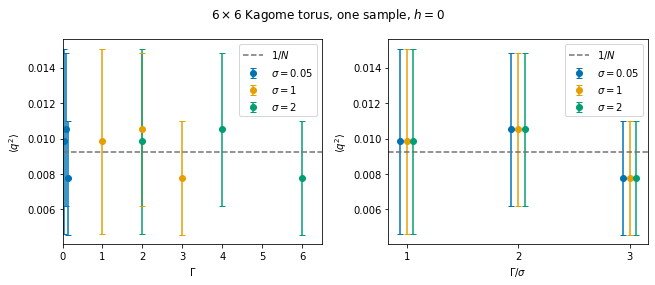

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(9.2, 4.0))
colors = {0.05: "#0072B2", 1.0: "#E69F00", 2.0: "#009E73"}
for sigma in sigmas:
    group = [row for row in rows if row["sigma"] == sigma]
    group.sort(key=lambda row: row["ratio"])
    axes[0].errorbar(
        [row["gamma"] for row in group],
        [row["q2"] for row in group],
        yerr=[row["q2_error"] for row in group],
        fmt="o",
        capsize=3,
        color=colors[sigma],
        label=rf"$\sigma = {sigma:g}$",
    )
    dodge = {0.05: -0.06, 1.0: 0.0, 2.0: 0.06}[sigma]
    axes[1].errorbar(
        [row["ratio"] + dodge for row in group],
        [row["q2"] for row in group],
        yerr=[row["q2_error"] for row in group],
        fmt="o",
        capsize=3,
        color=colors[sigma],
        label=rf"$\sigma = {sigma:g}$",
    )
for axis in axes:
    axis.axhline(1.0 / n_sites, color="0.45", linestyle="--", label="$1/N$")
    axis.set_ylabel(r"$\langle q^{2}\rangle$")
    axis.legend()
axes[0].set_xlabel(r"$\Gamma$")
axes[0].set_xlim(0.0, 6.5)
axes[1].set_xlabel(r"$\Gamma/\sigma$")
axes[1].set_xticks([1, 2, 3])
figure.suptitle(r"$6\times 6$ Kagome torus, one sample, $h = 0$")
figure.tight_layout()
plt.show()
